# DualPipe: a pipeline schedule with fewer bubbles, and communication hidden behind computation

*DeepSeek-V3 technical report, section 3.2.1. Notebook 6 of 8.*

**TL;DR.** A model too big for one GPU is cut into **stages** placed on different GPUs; a batch is cut into **micro-batches** that flow through the stages like items on an assembly line. The empty time at the start and end of the line is the **pipeline bubble**. DeepSeek-V3 adds a second cost: its mixture-of-experts layers send tokens between machines, and the paper reports that this communication takes about as long as the computation (a ratio of roughly 1:1). **DualPipe** answers both. It feeds micro-batches from **both ends** of the pipeline at once, splits the backward pass in two so that one half can fill gaps, and overlaps each forward chunk's computation with another chunk's communication. This notebook builds a small schedule simulator, checks it against the formulas in the paper's Table 2, shows how bubbles shrink, executes the schedules on real tensors to prove the gradients come out right, and models the computation-communication overlap. It is a simulation: a laptop cannot show wall-clock gains from GPU parallelism.

| step | what we do |
|---|---|
| 1 | pipeline parallelism and its bubble |
| 2 | splitting the backward pass into "input gradient" and "weight gradient" |
| 3 | a schedule simulator; 1F1B and the zero-bubble variant checked against Table 2 |
| 4 | bidirectional scheduling (DualPipe) |
| 5 | do these schedules compute the right gradients? (real tensors) |
| 6 | hiding all-to-all communication behind computation |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import dsv3kit as K                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. Pipeline parallelism and its bubble

Put the first quarter of the layers on GPU 0, the next on GPU 1, and so on: four **stages**. One micro-batch needs a **forward** chunk $F$ on each stage in order, then a **backward** chunk $B$ on each stage in reverse order. GPU $i$ cannot start micro-batch $m$'s forward before GPU $i-1$ finishes it, and cannot start its backward before GPU $i+1$ has finished the backward. The standard schedule, **1F1B**, runs a few forwards to fill the pipe, then alternates one forward with one backward, then drains. The idle time before the first forward arrives and after the last backward leaves is the bubble.

If a forward chunk takes $F$ and a full backward chunk takes $B$, the paper's Table 2 says the bubble of 1F1B on $PP$ stages is $(PP-1)(F+B)$ per GPU, independent of how many micro-batches you use. Making a batch bigger does not make the bubble smaller; it just makes it a smaller fraction of the whole.

![Paper Figure 5: an example DualPipe schedule for 8 pipeline ranks and 20 micro-batches in two directions.](../../assets/deepseek_v3/fig5_dualpipe.png)

*Figure 5 of the paper: an example DualPipe schedule for 8 pipeline ranks and 20 micro-batches in two directions. Orange is forward, green is backward, blue is "backward for weights". Cells enclosed in a shared border have overlapped computation and communication. We reproduce the comparison with a simulator below.*

Table 2 of the paper, for reference:

| method | bubble | parameters | activations |
|---|---|---|---|
| 1F1B | $(PP-1)(F+B)$ | 1x | $PP$ |
| ZB1P | $(PP-1)(F+B-2W)$ | 1x | $PP$ |
| DualPipe | $(\tfrac{PP}{2}-1)(F\&B+B-3W)$ | 2x | $PP+1$ |

($F$, $B$, $W$: time of a forward chunk, a full backward chunk, a "backward for weights" chunk; $F\&B$: time of a forward and a backward chunk overlapped.)

## 2. Splitting the backward pass

Why is there a $W$? A backward pass through a layer computes two different things:

- the gradient with respect to the layer's **input**, $\partial L/\partial \mathbf x$, which the *previous* stage is waiting for;
- the gradient with respect to the layer's **weights**, $\partial L/\partial W$, which **nobody else is waiting for**: it is only needed before the optimizer step.

The first is urgent, the second is not. ZeroBubble (Qi et al.) and DualPipe schedule them as separate chunks ($B_{in}$, often just written $B$, and $W$): do the urgent part immediately, and use $W$ to fill idle slots. The split must not change any gradient. Check on a two-layer network:

In [2]:
torch.manual_seed(0)
layer1, layer2 = nn.Linear(16, 32), nn.Linear(32, 8)
x = torch.randn(10, 16, requires_grad=True); target = torch.randn(10, 8)
h = torch.tanh(layer1(x)); out = layer2(h); loss = F.mse_loss(out, target)

# (a) the usual backward
loss.backward(retain_graph=True)
ref = {n: p.grad.clone() for n, p in list(layer1.named_parameters()) + [("l2." + n, p) for n, p in layer2.named_parameters()]}
ref_x = x.grad.clone()
for p in list(layer1.parameters()) + list(layer2.parameters()): p.grad = None
x.grad = None

# (b) split: first only the INPUT gradient chain (urgent) ...
g_out = torch.autograd.grad(loss, out, retain_graph=True)[0]
g_h = torch.autograd.grad(out, h, g_out, retain_graph=True)[0]                      # B_in of layer 2
g_pre = torch.autograd.grad(h, x, g_h, retain_graph=True)[0]                        # B_in of layer 1 (down to x)
# ... and LATER the weight gradients (deferred), in any order
gw2 = torch.autograd.grad(out, list(layer2.parameters()), g_out, retain_graph=True)            # W of layer 2
gw1 = torch.autograd.grad(h, list(layer1.parameters()), g_h)                                   # W of layer 1

split = {"weight": gw1[0], "bias": gw1[1], "l2.weight": gw2[0], "l2.bias": gw2[1]}
for k in split:
    print(f"{k:10s} max |split - usual| = {float((split[k] - ref[k]).abs().max()):.2e}")
print("input gradient max difference:", float((g_pre - ref_x).abs().max()))
check("split weight gradients equal the usual ones", all(torch.allclose(split[k], ref[k], atol=1e-6) for k in split))
check("split input gradient equals the usual one", torch.allclose(g_pre, ref_x, atol=1e-6))

weight     max |split - usual| = 0.00e+00
bias       max |split - usual| = 0.00e+00
l2.weight  max |split - usual| = 0.00e+00
l2.bias    max |split - usual| = 0.00e+00
input gradient max difference: 0.0
PASS - split weight gradients equal the usual ones 
PASS - split input gradient equals the usual one 


The weight gradients were computed *after* the whole input-gradient chain and came out identical. That is the freedom the schedulers exploit.

## 3. A schedule simulator

We make each chunk an **operation** with a duration, a device and dependencies, then simulate the devices. Operations for micro-batch $m$ in direction $d$ at stage $s$:

- $F(s)$ depends on $F(s-1)$;
- $B_{in}(s)$ depends on $B_{in}(s+1)$ and on $F(s)$ (the last stage depends only on its own $F$);
- $W(s)$ depends on $B_{in}(s)$ only.

Durations: $F=1$, $B_{in}=1$, $W=1$, so a full backward is $B = B_{in}+W = 2$, as in the usual rule of thumb that backward costs twice forward. Communication is ignored in this section (it comes back in step 6).

The simulator does not know about any particular schedule. It repeatedly picks, among all operations whose dependencies are satisfied, the one that can start earliest, breaking ties by priority ($B_{in}$ before $F$ before $W$), subject to a cap on how many forward chunks each device may hold unfinished (which bounds activation memory). For plain 1F1B we instead give each device its fixed order.

In [3]:
def build_ops(P, M_dir, dirs, F=1.0, Bin=1.0, W=1.0, split=True):
    ops = {}
    for d in dirs:
        for m in range(M_dir):
            for s in range(P):
                dev = s if d == 0 else P - 1 - s
                ops[("F", d, m, s)] = dict(dev=dev, dur=F, deps=[("F", d, m, s - 1)] if s > 0 else [])
                deps = [("F", d, m, s)] + ([("B", d, m, s + 1)] if s < P - 1 else [])
                ops[("B", d, m, s)] = dict(dev=dev, dur=(Bin if split else Bin + W), deps=deps)
                if split:
                    ops[("W", d, m, s)] = dict(dev=dev, dur=W, deps=[("B", d, m, s)])
    return ops

def one_f_one_b_order(P, M):
    order = {}
    for i in range(P):
        w = min(P - i - 1, M)
        seq = [("F", 0, m, i) for m in range(w)]
        nb = 0
        for j in range(M - w):
            seq += [("F", 0, w + j, i), ("B", 0, nb, i)]; nb += 1
        seq += [("B", 0, m, i) for m in range(nb, M)]
        order[i] = seq
    return order

In [4]:
def schedule(ops, P, order=None, limit=None, prio="BFW"):
    free = [0.0] * P; finish = {}; out = []
    remaining = {i: [k for k, o in ops.items() if o["dev"] == i] for i in range(P)}
    if order: pos = {i: 0 for i in range(P)}
    inflight = {}
    total = len(ops)
    while len(out) < total:
        best = None
        for dev in range(P):
            cands = [order[dev][pos[dev]]] if order and pos[dev] < len(order[dev]) else ([] if order else remaining[dev])
            for key in cands:
                op = ops[key]
                if any(d not in finish for d in op["deps"]): continue
                if limit and key[0] == "F":
                    lim = limit(dev, key[1])
                    if lim is not None and inflight.get((dev, key[1]), 0) >= lim: continue
                start = max([free[dev]] + [finish[d] for d in op["deps"]])
                score = (start, prio.index(key[0]), key[2], key[1])
                if best is None or score < best[0]: best = (score, dev, key, start)
        assert best is not None, "deadlock"
        _, dev, key, start = best
        end = start + ops[key]["dur"]
        finish[key] = end; free[dev] = end; out.append((dev, start, end, key)); remaining[dev].remove(key)
        if order: pos[dev] += 1
        if key[0] == "F": inflight[(dev, key[1])] = inflight.get((dev, key[1]), 0) + 1
        if key[0] == "B": inflight[(dev, key[1])] = inflight.get((dev, key[1]), 0) - 1
    return out

In [5]:
def stats(sched, P, split=True):
    mk = max(e for _, _, e, _ in sched)
    busy = [sum(e - s for d, s, e, _ in sched if d == i) for i in range(P)]
    # peak activations: allocated at F start, freed at W end (or B end)
    free_kind = "W" if split else "B"
    peaks = []
    for i in range(P):
        ev = []
        for d, s, e, k in sched:
            if d != i: continue
            if k[0] == "F": ev.append((s, +1))
            if k[0] == free_kind: ev.append((e, -1))
        ev.sort(key=lambda t: (t[0], t[1])); cur = pk = 0
        for _, dl in ev: cur += dl; pk = max(pk, cur)
        peaks.append(pk)
    return mk, [mk - b for b in busy], peaks

First the two cases where the paper gives a formula: 1F1B, and the zero-bubble variant (ZB1P) in which $W$ is separated. With $PP=8$ stages and 20 micro-batches (the paper's example):

In [6]:
P, M = 8, 20
Fd, Bind, Wd = 1.0, 1.0, 1.0                      # F, B_in, W; the full backward is B = B_in + W = 2
Bfull = Bind + Wd

# 1F1B: full backward chunks, a fixed order on every device
ops = build_ops(P, M, [0], Fd, Bind, Wd, split=False)
s_1f1b = schedule(ops, P, order=one_f_one_b_order(P, M))
mk1, bub1, _ = stats(s_1f1b, P, split=False)

# ZB1P-like: split backward, greedy, at most P - i unfinished forwards on device i (same memory cap as 1F1B)
ops = build_ops(P, M, [0], Fd, Bind, Wd)
s_zb = schedule(ops, P, limit=lambda dev, d: P - dev)
mkz, bubz, _ = stats(s_zb, P)

f1 = (P - 1) * (Fd + Bfull)
fz = (P - 1) * (Fd + Bfull - 2 * Wd)
ideal = M * (Fd + Bfull)
print(f"work per device: {ideal:.0f} time units for {M} micro-batches")
print(f"{'':8s} {'finish time':>12s} {'bubble (simulated)':>20s} {'bubble (Table 2)':>18s}")
print(f"{'1F1B':8s} {mk1:12.0f} {bub1[0]:20.1f} {f1:18.1f}")
print(f"{'ZB1P':8s} {mkz:12.0f} {bubz[0]:20.1f} {fz:18.1f}")
check("simulated 1F1B bubble equals the Table 2 formula (PP-1)(F+B)", abs(bub1[0] - f1) < 1e-9 and max(bub1) == min(bub1))
check("simulated ZB1P bubble equals (PP-1)(F+B-2W)", abs(bubz[0] - fz) < 1e-9)
check("splitting W out of the backward cuts the bubble by 3x here", bub1[0] / bubz[0] == 3)

work per device: 60 time units for 20 micro-batches
          finish time   bubble (simulated)   bubble (Table 2)
1F1B               81                 21.0               21.0
ZB1P               67                  7.0                7.0
PASS - simulated 1F1B bubble equals the Table 2 formula (PP-1)(F+B) 
PASS - simulated ZB1P bubble equals (PP-1)(F+B-2W) 
PASS - splitting W out of the backward cuts the bubble by 3x here 


Both match the paper's formulas **exactly**, which tells us the simulator and the dependency rules are right: the 1F1B result comes from a fixed order, the ZB1P result from the greedy rule alone, and it lands on the formula's value of 7 time units (against 21 for 1F1B).

## 4. Bidirectional scheduling

1F1B and ZB1P still have a start-up cost: the last stage has nothing to do until the first micro-batch has crossed the whole pipe. DualPipe's central trick is to run **two pipelines at once in opposite directions**. Half of the micro-batches enter at GPU 0 and travel to GPU $PP-1$ as usual; the other half enter at GPU $PP-1$ and travel to GPU 0. Every GPU holds **two stages**, stage $i$ for the first direction and stage $PP-1-i$ for the second (so each stage's weights exist on two GPUs: the 2x parameters of Table 2; the paper notes this is cheap because its expert parallelism is large). While GPU 0 waits for the first pipeline, the second pipeline's work arrives at it first, and vice versa. The memory cap is split: $PP-i$ unfinished forwards in the first direction plus $i+1$ in the second, so $PP+1$ in total, which is the table's activation entry.

In [7]:
ops = build_ops(P, M // 2, [0, 1], Fd, Bind, Wd)                      # 10 micro-batches per direction
s_dual = schedule(ops, P, limit=lambda dev, d: (P - dev) if d == 0 else dev + 1)
mkd, bubd, _ = stats(s_dual, P)
fd = (P / 2 - 1) * ((Fd + Bfull) + Bfull - 3 * Wd)                    # Table 2 with F&B = F + B (no overlap gain yet)
print(f"{'':8s} {'finish time':>12s} {'bubble (simulated)':>20s} {'bubble (Table 2)':>18s}")
for name, mk, bu, ff in [("1F1B", mk1, bub1[0], f1), ("ZB1P", mkz, bubz[0], fz), ("DualPipe", mkd, bubd[0], fd)]:
    print(f"{name:8s} {mk:12.0f} {bu:20.1f} {ff:18.1f}")
print("\nwork per device is the same for all three:", ideal, "time units")
check("DualPipe finishes sooner than ZB1P and ZB1P sooner than 1F1B", mkd < mkz < mk1)
check("our greedy bidirectional schedule has a bubble no larger than Table 2's value", bubd[0] <= fd + 1e-9, f"({bubd[0]:.1f} vs {fd:.1f})")
check("every device has the same total work in all three schedules", abs(sum(e - s for d, s, e, k in s_dual if d == 3) - ideal) < 1e-9)

          finish time   bubble (simulated)   bubble (Table 2)
1F1B               81                 21.0               21.0
ZB1P               67                  7.0                7.0
DualPipe           63                  3.0                6.0

work per device is the same for all three: 60.0 time units
PASS - DualPipe finishes sooner than ZB1P and ZB1P sooner than 1F1B 
PASS - our greedy bidirectional schedule has a bubble no larger than Table 2's value (3.0 vs 6.0)
PASS - every device has the same total work in all three schedules 


Directionally this matches the paper: bidirectional feeding removes most of the remaining bubble. Our number (3) is **below** the formula's (6). We do not claim our simulator beats the paper's schedule. The formula describes DualPipe's hand-designed schedule, whose forward and backward chunks are paired into fused $F\&B$ blocks, and in which communication and synchronisation take real time. Our simulator has zero communication cost, perfectly divisible chunks and a free choice of ordering at every step, so it is an idealised bound, not a reproduction.

Two more properties the paper states. **Bubbles do not grow with the number of micro-batches** (and neither does activation memory); with $PP=8$:

In [8]:
print(f"{'micro-batches':>14s} {'1F1B':>8s} {'ZB1P':>8s} {'DualPipe':>10s}   (bubble per device)")
bubs = []
for Mx in [8, 16, 20, 40, 80]:
    a = stats(schedule(build_ops(P, Mx, [0], Fd, Bind, Wd, split=False), P, order=one_f_one_b_order(P, Mx)), P, False)[1][0]
    b = stats(schedule(build_ops(P, Mx, [0], Fd, Bind, Wd), P, limit=lambda dev, d: P - dev), P)[1][0]
    c = stats(schedule(build_ops(P, Mx // 2, [0, 1], Fd, Bind, Wd), P, limit=lambda dev, d: (P - dev) if d == 0 else dev + 1), P)[1][0]
    bubs.append((Mx, a, b, c)); print(f"{Mx:14d} {a:8.1f} {b:8.1f} {c:10.1f}")
print("\nbubble as a fraction of the finish time at 20 micro-batches: 1F1B %.0f%%, ZB1P %.0f%%, DualPipe %.0f%%" % (100 * bub1[0] / mk1, 100 * bubz[0] / mkz, 100 * bubd[0] / mkd))
check("bubble does not depend on the number of micro-batches for any of the three", len({b[1] for b in bubs}) == 1 and len({b[2] for b in bubs}) == 1 and max(b[3] for b in bubs) - min(b[3] for b in bubs) <= 1.0)

 micro-batches     1F1B     ZB1P   DualPipe   (bubble per device)
             8     21.0      7.0        3.0


            16     21.0      7.0        3.0


            20     21.0      7.0        3.0


            40     21.0      7.0        3.0


            80     21.0      7.0        3.0

bubble as a fraction of the finish time at 20 micro-batches: 1F1B 26%, ZB1P 10%, DualPipe 5%
PASS - bubble does not depend on the number of micro-batches for any of the three 


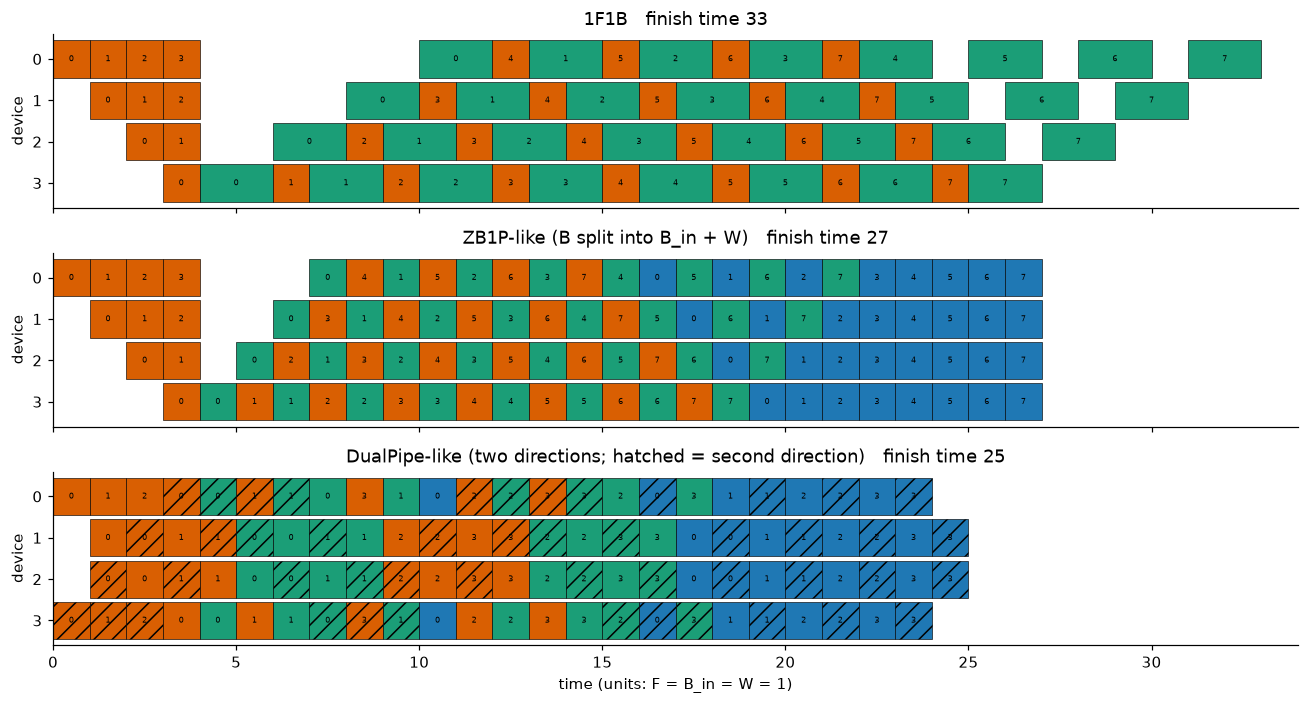

In [9]:
def gantt(ax, sched, P, title, tmax):
    col = {"F": C["orange"], "B": C["green"], "W": C["blue"]}
    for dev, s, e, k in sched:
        ax.barh(dev, e - s, left=s, color=col[k[0]], edgecolor="k", linewidth=.4, hatch="//" if k[1] == 1 else None, height=.9)
        if e - s >= 1: ax.text((s + e) / 2, dev, str(k[2]), ha="center", va="center", fontsize=5.5)
    ax.set(xlim=(0, tmax), ylim=(P - .4, -.6), title=title, yticks=range(P), ylabel="device"); ax.grid(False)

Pv, Mv = 4, 8
sv1 = schedule(build_ops(Pv, Mv, [0], Fd, Bind, Wd, split=False), Pv, order=one_f_one_b_order(Pv, Mv))
svz = schedule(build_ops(Pv, Mv, [0], Fd, Bind, Wd), Pv, limit=lambda dev, d: Pv - dev)
svd = schedule(build_ops(Pv, Mv // 2, [0, 1], Fd, Bind, Wd), Pv, limit=lambda dev, d: (Pv - dev) if d == 0 else dev + 1)
tmax = max(max(e for _, _, e, _ in s) for s in (sv1, svz, svd)) + 1
fig, ax = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True)
for a_, s_, t_ in zip(ax, (sv1, svz, svd), ("1F1B", "ZB1P-like (B split into B_in + W)", "DualPipe-like (two directions; hatched = second direction)")):
    gantt(a_, s_, Pv, t_ + f"   finish time {max(e for _, _, e, _ in s_):.0f}", tmax)
ax[-1].set_xlabel("time (units: F = B_in = W = 1)")
plt.tight_layout(); plt.show()

Orange: forward, green: backward (input gradient; for 1F1B the full backward of length 2), blue: weight-gradient chunks, white: idle. With only 4 devices and 8 micro-batches the differences are visible at the corners: 1F1B has large triangles of idle time at both ends; the others fill the end with blue $W$ chunks and, for the bidirectional schedule, start every device busy.

## 5. Do these schedules compute the right gradients?

A schedule that is shorter but wrong is worthless. To check the **dependency structure** (not just the timing) we execute each simulated schedule on a real 4-stage network with real tensors, operation by operation, in the order the schedule gives, and compare the accumulated gradients with an ordinary single backward pass over the whole batch. For DualPipe the two directions share one model (logical stage $s$ is the same weights whichever GPU holds it), so gradients from both directions add into the same parameters.

In [10]:
def run_on_tensors(sched, P, M_total, split, seed=0):
    torch.manual_seed(seed)
    stages = nn.ModuleList([nn.Sequential(nn.Linear(16, 16), nn.Tanh()) for _ in range(P)])
    X, Y = torch.randn(M_total * 4, 16), torch.randn(M_total * 4, 16)
    mb = lambda d, m: d * (M_total // (2 if any(k[1] == 1 for _, _, _, k in sched) else 1)) + m     # global micro-batch id
    acts, gout = {}, {}
    for p in stages.parameters(): p.grad = None
    for dev, st, en, key in sorted(sched, key=lambda t: (t[1], t[2])):
        kind, d, m, s = key
        i = mb(d, m)
        if kind == "F":
            inp = X[i * 4:(i + 1) * 4] if s == 0 else acts[(d, m, s - 1)][1].detach().requires_grad_()
            if s == 0: inp = inp.clone().requires_grad_()
            acts[(d, m, s)] = (inp, stages[s](inp))
        else:
            inp, out = acts[(d, m, s)]
            if kind == "B":
                if s == P - 1:
                    loss = F.mse_loss(out, Y[i * 4:(i + 1) * 4]) / M_total
                    g = torch.autograd.grad(loss, out, retain_graph=True)[0]
                else:
                    g = gout[(d, m, s)]
                gout[("own", d, m, s)] = g
                gi = torch.autograd.grad(out, inp, g, retain_graph=True)[0]
                if s > 0: gout[(d, m, s - 1)] = gi
                if not split:                                           # full backward: weights too
                    for p, gp in zip(stages[s].parameters(), torch.autograd.grad(out, list(stages[s].parameters()), g)):
                        p.grad = gp if p.grad is None else p.grad + gp
            elif kind == "W":
                g = gout[("own", d, m, s)]
                for p, gp in zip(stages[s].parameters(), torch.autograd.grad(out, list(stages[s].parameters()), g)):
                    p.grad = gp if p.grad is None else p.grad + gp
    got = [p.grad.clone() for p in stages.parameters()]
    # reference: one ordinary backward pass over the full batch
    for p in stages.parameters(): p.grad = None
    h = X
    for st_ in stages: h = st_(h)
    (F.mse_loss(h, Y)).backward()
    ref = [p.grad.clone() for p in stages.parameters()]
    return max(float((a - b).abs().max()) for a, b in zip(got, ref)), max(float(b.abs().max()) for b in ref)

Pt, Mt = 4, 8
cases = {
    "1F1B": (schedule(build_ops(Pt, Mt, [0], 1, 1, 1, split=False), Pt, order=one_f_one_b_order(Pt, Mt)), False),
    "ZB1P-like": (schedule(build_ops(Pt, Mt, [0], 1, 1, 1), Pt, limit=lambda dev, d: Pt - dev), True),
    "DualPipe-like": (schedule(build_ops(Pt, Mt // 2, [0, 1], 1, 1, 1), Pt, limit=lambda dev, d: (Pt - dev) if d == 0 else dev + 1), True),
}
for name, (sc, split) in cases.items():
    diff, scale = run_on_tensors(sc, Pt, Mt, split)
    print(f"{name:14s} max |pipeline gradient - single-pass gradient| = {diff:.2e}   (gradient scale {scale:.2e})")
    check(f"{name}: schedule reproduces the exact gradients", diff < 1e-6)

1F1B           max |pipeline gradient - single-pass gradient| = 7.45e-09   (gradient scale 7.19e-02)
PASS - 1F1B: schedule reproduces the exact gradients 
ZB1P-like      max |pipeline gradient - single-pass gradient| = 7.45e-09   (gradient scale 7.19e-02)
PASS - ZB1P-like: schedule reproduces the exact gradients 
DualPipe-like  max |pipeline gradient - single-pass gradient| = 7.45e-09   (gradient scale 7.19e-02)
PASS - DualPipe-like: schedule reproduces the exact gradients 


All three schedules, including the bidirectional one with weight-gradient chunks executed late and out of order, reproduce the ordinary gradients to float precision. The micro-batch order and the position of $W$ do not matter, only the dependencies do.

## 6. Hiding the all-to-all communication

V3's MoE layers route each token to experts on other GPUs, so each layer has two communication steps, a **dispatch** (send tokens to their experts) and a **combine** (bring the outputs back), in the forward pass and again in the backward pass. The paper reports that without care this makes the computation-to-communication ratio about **1:1**: half the time the GPUs are waiting on the network.

DualPipe's second idea works at a finer granularity than the schedule above. It cuts each chunk into the parts attention, dispatch, MLP, combine (with the backward's attention and MLP further split into input-gradient and weight-gradient parts), and **interleaves the parts of one forward chunk and one backward chunk** so that whenever the network is busy with one of them, the GPU is computing the other.

![Paper Figure 4: overlapping strategy for a forward and a backward chunk. Computation on the top row, communication below. Both the all-to-all and the pipeline communication are hidden.](../../assets/deepseek_v3/fig4_overlap.png)

*Figure 4 of the paper. Orange: forward; green: backward for input; blue: backward for weights; purple: pipeline communication; red: barriers.*

We model one such pair with two resources, a compute stream and a communication stream. A forward chunk is attention (1) → dispatch (1) → MLP (1) → combine (1): 2 units of compute and 2 of communication, the paper's 1:1 ratio. The backward chunk mirrors it in reverse and, as usual, has twice the compute (an input-gradient and a weight-gradient step for each of attention and MLP) and the same two communication steps. For the pair that makes 6 units of compute and 4 of communication. Compute and network can run in parallel; within a chunk the order is fixed by data dependencies. We compare running the two chunks one after the other with a greedy two-stream schedule.

compute total 6, communication total 4  (ratio comm : comp = 0.67)
one chunk after the other, no overlap : 10 time units
overlapped on two streams (greedy)    : 6.0 time units
lower bound (the busier stream)       : 6 time units
communication left exposed            : 0.0 units


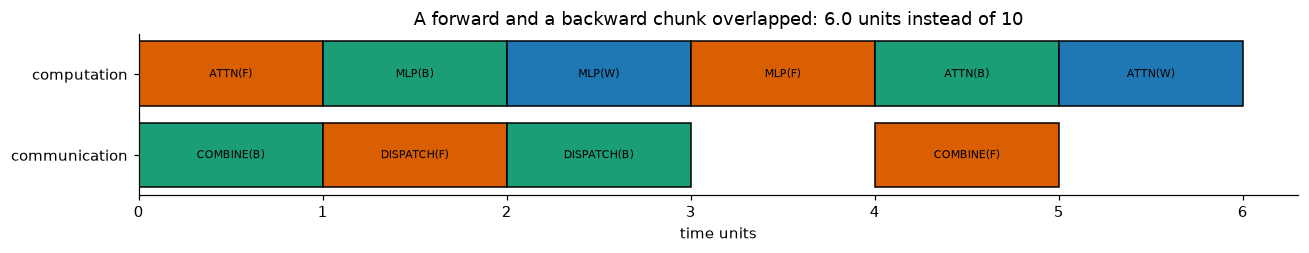

PASS - overlapping saves time compared with running the chunks back to back 
PASS - the overlapped time is within 1 unit of the lower bound (compute-bound) (6.0 vs 6)
PASS - communication is hidden except for at most one unit 


In [11]:
# tasks: name -> (resource, duration, dependencies)
fwd = {"ATTN(F)": ("comp", 1, []), "DISPATCH(F)": ("comm", 1, ["ATTN(F)"]), "MLP(F)": ("comp", 1, ["DISPATCH(F)"]), "COMBINE(F)": ("comm", 1, ["MLP(F)"])}
bwd = {"COMBINE(B)": ("comm", 1, []), "MLP(B)": ("comp", 1, ["COMBINE(B)"]), "MLP(W)": ("comp", 1, ["MLP(B)"]),
       "DISPATCH(B)": ("comm", 1, ["MLP(B)"]), "ATTN(B)": ("comp", 1, ["DISPATCH(B)"]), "ATTN(W)": ("comp", 1, ["ATTN(B)"])}
tasks = {**fwd, **bwd}

def two_streams(tasks, order):
    free = {"comp": 0.0, "comm": 0.0}; fin = {}; out = []
    todo = list(order)
    while todo:
        best = None
        for name in todo:
            res, dur, deps = tasks[name]
            if any(d not in fin for d in deps): continue
            start = max([free[res]] + [fin[d] for d in deps])
            if best is None or (start, order.index(name)) < (best[0], order.index(best[1])): best = (start, name)
        start, name = best; res, dur, deps = tasks[name]
        fin[name] = start + dur; free[res] = fin[name]; out.append((res, start, fin[name], name)); todo.remove(name)
    return out, max(fin.values())

comp_total = sum(d for r, d, _ in tasks.values() if r == "comp"); comm_total = sum(d for r, d, _ in tasks.values() if r == "comm")
sequential = sum(d for _, d, _ in tasks.values())                                          # one task at a time: no overlap at all
# the pair in a good order: backward-chunk work is interleaved with forward-chunk work
order = ["COMBINE(B)", "ATTN(F)", "MLP(B)", "DISPATCH(F)", "MLP(W)", "MLP(F)", "DISPATCH(B)", "COMBINE(F)", "ATTN(B)", "ATTN(W)"]
sched6, overlapped = two_streams(tasks, order)
bound = max(comp_total, comm_total)
print(f"compute total {comp_total}, communication total {comm_total}  (ratio comm : comp = {comm_total / comp_total:.2f})")
print(f"one chunk after the other, no overlap : {sequential} time units")
print(f"overlapped on two streams (greedy)    : {overlapped} time units")
print(f"lower bound (the busier stream)       : {bound} time units")
print(f"communication left exposed            : {overlapped - comp_total:.1f} units")

fig, ax = plt.subplots(figsize=(12, 2.4))
for res, s_, e_, name in sched6:
    y = 1 if res == "comp" else 0
    ax.barh(y, e_ - s_, left=s_, color=C["orange"] if "(F)" in name else (C["blue"] if "(W)" in name else C["green"]), edgecolor="k", height=.8)
    ax.text((s_ + e_) / 2, y, name, ha="center", va="center", fontsize=7)
ax.set(yticks=[0, 1], yticklabels=["communication", "computation"], xlabel="time units", title=f"A forward and a backward chunk overlapped: {overlapped} units instead of {sequential}"); ax.grid(False)
plt.tight_layout(); plt.show()
check("overlapping saves time compared with running the chunks back to back", overlapped < sequential)
check("the overlapped time is within 1 unit of the lower bound (compute-bound)", overlapped - bound <= 1.0 + 1e-9, f"({overlapped} vs {bound})")
check("communication is hidden except for at most one unit", overlapped - comp_total <= 1.0 + 1e-9)

Running the two chunks back to back costs 10 units; overlapped on two streams they take 6, the amount of computation alone: in this idealised model all communication is hidden, and a step takes 60% of the original time. On real hardware overlap is never that perfect: the paper adjusts by hand the number of GPU streaming multiprocessors given to communication, because communication kernels themselves occupy compute units (20 SMs in their setting). We ignore that cost, we use unit durations we chose, and we model one layer's pair, not the full interleaving across the pipeline.

The paper's conclusion is that as long as the compute-to-communication ratio stays constant, "fine-grained experts across nodes" remain affordable with near-zero all-to-all overhead. We cannot test the real claim here; the model only shows why the interleaving can work.

## What to take away

1. **The pipeline bubble is a start-up and drain cost**, $(PP-1)(F+B)$ for 1F1B, independent of the number of micro-batches.
2. **Splitting the backward** into an urgent input-gradient part and a deferrable weight-gradient part lets the weight-gradient chunks fill idle slots (ZB1P: 3x smaller bubble than 1F1B at $PP=8$). The split leaves gradients unchanged.
3. **DualPipe feeds micro-batches from both ends**, so no GPU waits for the first pipeline to reach it. It costs a second copy of each stage's weights and one more unit of activation memory.
4. **Overlapping a forward chunk with a backward chunk** keeps GPUs computing while the all-to-all runs, which matters when compute and communication are 1:1.
5. All of this was checked against Table 2 (1F1B and ZB1P exactly) and by executing schedules on real tensors.

## What this notebook does not show
- **Real speed.** Everything is a simulation of times we chose (F = B_in = W = 1, communication 1:1). No GPUs, no network, no measured throughput.
- **The paper's DualPipe schedule itself.** Ours is a greedy list scheduler with the same dependencies and the same memory caps. Its bubble (3 units) is lower than the formula's (6) because it is idealised: no communication cost, no fused-pair constraints, chunks freely reordered. Do not read it as an improvement over the paper.
- **Memory.** The activation caps are inputs to our simulator (they enforce the $PP$ and $PP+1$ of Table 2 by construction), not independently measured; peak activation memory with deferred $W$ chunks is a separate question we did not study.
- **Communication kernels,** the SM allocation, the IB/NVLink path of tokens, and node-limited routing's effect on traffic.

*Next:* notebook 7 explains how V3's context window was extended with YaRN.

In [12]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 15 | failed: 0
